In [ ]:

from google.colab import files
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Upload both metric CSV files, must select both files together otherwise code will not work
files.upload()

depth_path = Path('MMA3001_appletree_depthmetric.csv')
common_path = Path('MMA3001_appletree_commonsupportmetric.csv')

depth = pd.read_csv(depth_path)
common = pd.read_csv(common_path)

# Check that both files contain matching experiments
assert len(depth) == 48 and len(common) == 48, 'Expected 48 rows in each CSV.'

assert set(zip(depth.image, depth.design, depth.method)) == set(
    zip(common.image, common.design, common.method)
), 'Experiment rows do not match.'


Saving MMA3001_appletree_commonsupportmetric.csv to MMA3001_appletree_commonsupportmetric.csv
Saving MMA3001_appletree_depthmetric.csv to MMA3001_appletree_depthmetric.csv


In [3]:
# Calculate the average (median) performance metrics
OUT = Path('MMA3001_appletree_figures')
OUT.mkdir(exist_ok=True)

depth_summary = depth.groupby(['design', 'method'])[
    ['rmse', 'mae', 'coverage', 'runtime_seconds']
].median().round(4)

common_summary = common.groupby(['design', 'method'])[
    ['shared_rmse', 'shared_mae', 'common_fraction', 'individual_coverage']
].median().round(4)

print('DEPTH METRICS')
print(depth_summary)

print('\nCOMMON-SUPPORT METRICS')
print(common_summary)

depth_summary.to_csv(OUT / 'depth_summary.csv')
common_summary.to_csv(OUT / 'commonsupport_summary.csv')


DEPTH METRICS
                             rmse     mae  coverage  runtime_seconds
design            method                                            
random_pixels     idw      1.2918  0.3806    1.0000           0.0994
                  nearest  1.6352  0.3417    1.0000           0.0303
spatial_blocks_12 idw      3.6333  1.1459    0.9393           0.0960
                  nearest  4.2781  1.1198    0.9932           0.0280

COMMON-SUPPORT METRICS
                           shared_rmse  shared_mae  common_fraction  \
design            method                                              
random_pixels     idw           1.2918      0.3806           1.0000   
                  nearest       1.6352      0.3417           1.0000   
spatial_blocks_12 idw           3.6333      1.1459           0.9393   
                  nearest       4.0222      1.0571           0.9393   

                           individual_coverage  
design            method                        
random_pixels     idw  

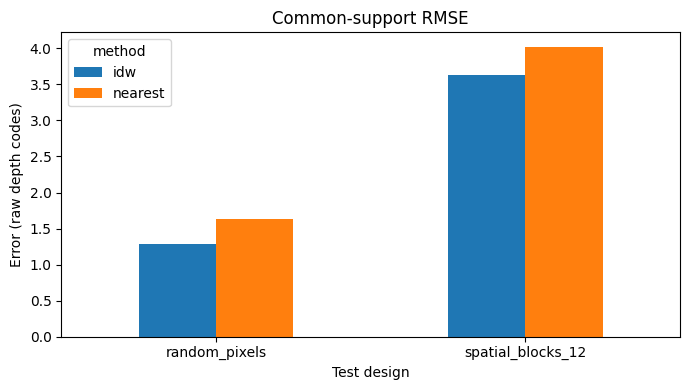

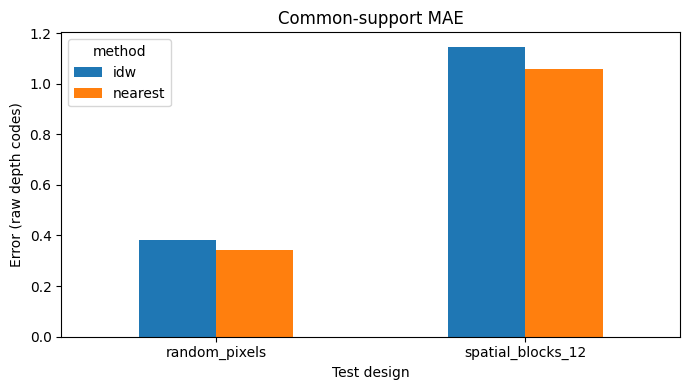

In [4]:
# Error rate comparison between RMSE and MAE
for metric, title, filename in [
    ('shared_rmse', 'Common-support RMSE', 'common_rmse.png'),
    ('shared_mae', 'Common-support MAE', 'common_mae.png')
]:
    table = common.pivot_table(
        index='design',
        columns='method',
        values=metric,
        aggfunc='median'
    )

    ax = table.plot(kind='bar', figsize=(7, 4))
    ax.set_title(title)
    ax.set_xlabel('Test design')
    ax.set_ylabel('Error (raw depth codes)')
    ax.tick_params(axis='x', rotation=0)

    plt.tight_layout()
    plt.savefig(OUT / filename, dpi=160)
    plt.show()


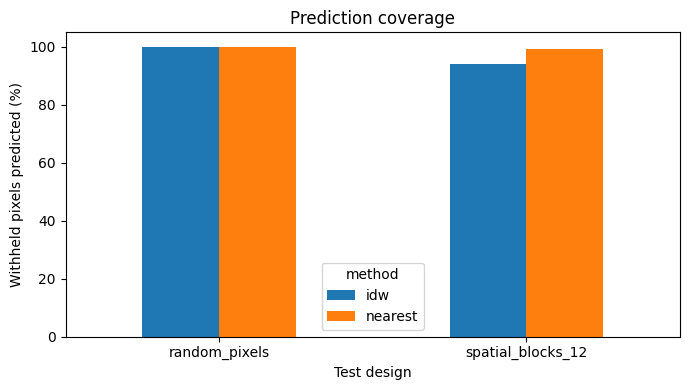

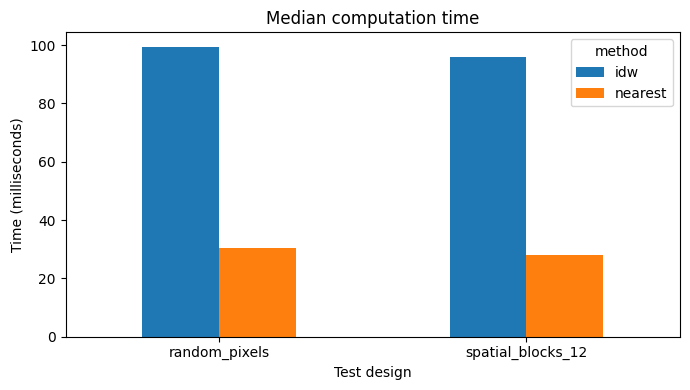

In [5]:

# Prediction coverage and Algorithm runtime
coverage = depth.pivot_table(
    index='design',
    columns='method',
    values='coverage',
    aggfunc='median'
) * 100

ax = coverage.plot(kind='bar', figsize=(7, 4))
ax.set_title('Prediction coverage')
ax.set_ylabel('Withheld pixels predicted (%)')
ax.set_xlabel('Test design')
ax.set_ylim(0, 105)
ax.tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.savefig(OUT / 'coverage.png', dpi=160)
plt.show()

runtime = depth.pivot_table(
    index='design',
    columns='method',
    values='runtime_seconds',
    aggfunc='median'
) * 1000

ax = runtime.plot(kind='bar', figsize=(7, 4))
ax.set_title('Median computation time')
ax.set_ylabel('Time (milliseconds)')
ax.set_xlabel('Test design')
ax.tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.savefig(OUT / 'runtime.png', dpi=160)
plt.show()


method     idw  nearest
season                 
Summer  3.3452   3.5682
Winter  3.8165   4.2583


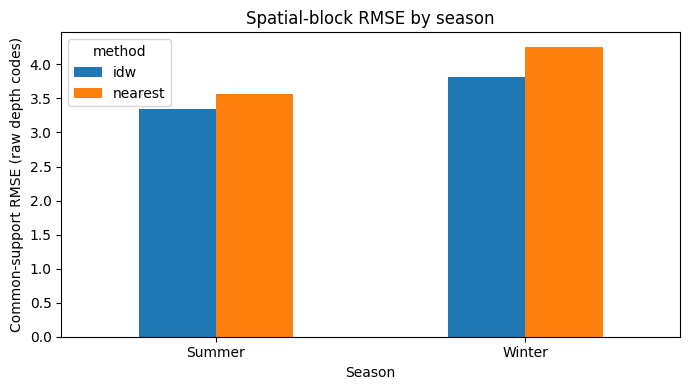

In [6]:
# Performance of each method across each season
blocked = common[common['design'] == 'spatial_blocks_12']

seasonal = blocked.pivot_table(
    index='season',
    columns='method',
    values='shared_rmse',
    aggfunc='median'
)

print(seasonal.round(4))

ax = seasonal.plot(kind='bar', figsize=(7, 4))
ax.set_title('Spatial-block RMSE by season')
ax.set_xlabel('Season')
ax.set_ylabel('Common-support RMSE (raw depth codes)')
ax.tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.savefig(OUT / 'seasonal_rmse.png', dpi=160)
plt.show()


In [7]:
import shutil

packet = shutil.make_archive(
    'MMA3001_appletree_results',
    'zip',
    OUT
)

print('Created:', packet)
files.download(packet)


Created: /content/MMA3001_appletree_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>